# MineGuard — Model Training (NASA C-MAPSS FD001 Edition)

### Why this notebook replaces `train_model_v3.ipynb`

The previous version trained on the **AI4I 2020** dataset, which has **no real RUL label**.
`RUL_hours` was invented as `MAX_WEAR × (1 − (wear/MAX_WEAR)^k)` — a formula with no
scientific backing, built from a feature (`component_wear_hrs`) that was also fed into the
model as an input. The reported R² ≈ 0.98 mostly reflected the model re-deriving that
formula, not learning real degradation behaviour.

This notebook uses **NASA's C-MAPSS FD001** turbofan degradation dataset instead. Every
engine in this dataset is run under simulation **until it actually fails**, so:

> `RUL = (cycle at which the engine failed) − (current cycle)`

is a **true, observed label** — not something we derive from our own assumptions. The only
processing decision we make on top of it is a *ceiling clip* at 125 cycles, which is a
long-standing, widely-cited convention in the C-MAPSS literature (Heimes, 2008; Saxena et
al., 2008; Zheng et al., 2017) — not an invented curve. The reasoning and citations are
given in the RUL section below.

### Workflow in this notebook
1. Load & explore FD001 (train / test / RUL files)
2. Feature selection (drop sensors with ~zero variance — well documented in the literature)
3. Construct the true RUL label + apply the standard ceiling clip
4. **Group-aware** train / validation / test split (no engine's cycles ever span two sets)
5. Hyperparameter tuning — `RandomizedSearchCV` + `GroupKFold` — for XGBoost, Gradient
   Boosting, Random Forest, AdaBoost, and an optional small ANN (MLP)
6. Refit tuned models on the full training pool, cross-validate, then evaluate **once** on
   the untouched test set
7. Pick the best model on test performance, build a Voting Ensemble, save artifacts


## Step 1 — Imports

In [1]:

import os, time, json, warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import GroupShuffleSplit, GroupKFold, RandomizedSearchCV, cross_val_score
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import (GradientBoostingRegressor, RandomForestRegressor,
                               AdaBoostRegressor, VotingRegressor)
from sklearn.tree import DecisionTreeRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error
import xgboost as xgb
import shap

sns.set_style('darkgrid')
RANDOM_STATE = 42
print('All imports OK')


All imports OK


## Step 2 — Load FD001

The three official files (`train_FD001.txt`, `test_FD001.txt`, `RUL_FD001.txt`) are
expected in `../dataset/CMAPSSData/`. If they aren't there, this cell downloads them
automatically from a public GitHub mirror of the NASA Prognostics Data Repository.


In [2]:

DATA_DIR = os.path.join('..', 'dataset', 'CMAPSSData')
FILES = ['train_FD001.txt', 'test_FD001.txt', 'RUL_FD001.txt']
MIRROR = 'https://raw.githubusercontent.com/mapr-demos/predictive-maintenance/master/notebooks/jupyter/Dataset/CMAPSSData/'

os.makedirs(DATA_DIR, exist_ok=True)
for fname in FILES:
    fpath = os.path.join(DATA_DIR, fname)
    if not os.path.isfile(fpath):
        import urllib.request
        print(f'Downloading {fname} ...')
        urllib.request.urlretrieve(MIRROR + fname, fpath)
    else:
        print(f'{fname} found locally.')

index_names   = ['unit_number', 'time_cycles']
setting_names = ['setting_1', 'setting_2', 'setting_3']
sensor_names  = [f'sensor_{i}' for i in range(1, 22)]
col_names     = index_names + setting_names + sensor_names

train_df = pd.read_csv(os.path.join(DATA_DIR, 'train_FD001.txt'), sep=r'\s+', header=None, names=col_names)
test_df  = pd.read_csv(os.path.join(DATA_DIR, 'test_FD001.txt'),  sep=r'\s+', header=None, names=col_names)
rul_df   = pd.read_csv(os.path.join(DATA_DIR, 'RUL_FD001.txt'),   sep=r'\s+', header=None, names=['RUL'])

print('train_df:', train_df.shape, '| engines:', train_df.unit_number.nunique())
print('test_df :', test_df.shape,  '| engines:', test_df.unit_number.nunique())
print('rul_df  :', rul_df.shape)
train_df.head(3)


train_FD001.txt found locally.
test_FD001.txt found locally.
RUL_FD001.txt found locally.
train_df: (20631, 26) | engines: 100
test_df : (13096, 26) | engines: 100
rul_df  : (100, 1)


,unit_number,time_cycles,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


## Step 3 — Quick EDA: engine lifespans

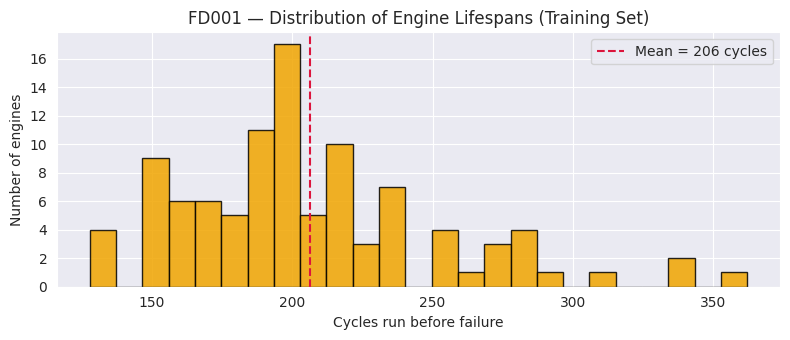

count    100.000000
mean     206.310000
std       46.342749
min      128.000000
25%      177.000000
50%      199.000000
75%      229.250000
max      362.000000
Name: time_cycles, dtype: float64


In [3]:

life = train_df.groupby('unit_number')['time_cycles'].max()
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.hist(life, bins=25, color='#f0a500', edgecolor='black', alpha=0.85)
ax.axvline(life.mean(), color='crimson', linestyle='--', label=f'Mean = {life.mean():.0f} cycles')
ax.set_xlabel('Cycles run before failure')
ax.set_ylabel('Number of engines')
ax.set_title('FD001 — Distribution of Engine Lifespans (Training Set)')
ax.legend()
plt.tight_layout()
plt.savefig('engine_lifespan_distribution.png', dpi=120)
plt.show()
print(life.describe())


## Step 4 — Feature selection

FD001 has a **single operating condition** (per NASA's own documentation) and several
sensors are physically constant under that condition. We confirm this empirically rather
than assuming it — any column with ~zero standard deviation carries no predictive signal
and is dropped.


In [4]:

candidate_cols = setting_names + sensor_names
stds = train_df[candidate_cols].std().sort_values()
print(stds)

DROP_COLS = stds[stds < 1e-2].index.tolist()
FEATURES  = [c for c in sensor_names if c not in DROP_COLS]
print(f'\\nDropped ({len(DROP_COLS)}):', DROP_COLS)
print(f'Kept as model features ({len(FEATURES)}):', FEATURES)


sensor_1     0.000000e+00
setting_3    0.000000e+00
sensor_10    0.000000e+00
sensor_19    0.000000e+00
sensor_18    0.000000e+00
sensor_16    3.469531e-18
sensor_5     5.329200e-15
setting_2    2.930621e-04
sensor_6     1.388985e-03
setting_1    2.187313e-03
sensor_15    3.750504e-02
sensor_8     7.098548e-02
sensor_13    7.191892e-02
sensor_21    1.082509e-01
sensor_20    1.807464e-01
sensor_11    2.670874e-01
sensor_2     5.000533e-01
sensor_12    7.375534e-01
sensor_7     8.850923e-01
sensor_17    1.548763e+00
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_14    1.907618e+01
sensor_9     2.208288e+01
dtype: float64
\nDropped (10): ['sensor_1', 'setting_3', 'sensor_10', 'sensor_19', 'sensor_18', 'sensor_16', 'sensor_5', 'setting_2', 'sensor_6', 'setting_1']
Kept as model features (14): ['sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## Step 5 — Sensor legend (for later dashboard mapping)

| Sensor | Physical meaning | Unit |
|---|---|---|
| sensor_2  | Total temperature at LPC outlet (T24) | °R |
| sensor_3  | Total temperature at HPC outlet (T30) | °R |
| sensor_4  | Total temperature at LPT outlet (T50) | °R |
| sensor_7  | Total pressure at HPC outlet (P30) | psia |
| sensor_8  | Physical fan speed (Nf) | rpm |
| sensor_9  | Physical core speed (Nc) | rpm |
| sensor_11 | Static pressure at HPC outlet (Ps30) | psia |
| sensor_12 | Ratio of fuel flow to Ps30 (phi) | pps/psi |
| sensor_13 | Corrected fan speed (NRf) | rpm |
| sensor_14 | Corrected core speed (NRc) | rpm |
| sensor_15 | Bypass ratio (BPR) | — |
| sensor_17 | Bleed enthalpy (htBleed) | — |
| sensor_20 | HPT coolant bleed (W31) | lbm/s |
| sensor_21 | LPT coolant bleed (W32) | lbm/s |

This is kept here so the eventual backend (`app_v4.py`) can present these with clear,
recruiter-and-engineer-friendly labels instead of raw `sensor_N` names.


## Step 6 — Target label: true RUL (with the standard ceiling clip)

**The label itself is not invented.** For every row, RUL is exactly:

```
RUL = (last cycle NASA recorded for that engine) − (current cycle)
```

That's it — it's the literal, observed number of cycles until the engine failed in
simulation. There is no formula being fit to make the numbers "look right."

**The only transformation we apply is a clip at 125 cycles**, and here's why: in the first
~100+ cycles of an engine's life, sensor readings barely differ whether the engine will
ultimately fail at cycle 150 or cycle 350 — there's no observable degradation yet. Asking a
model to tell those two apart from sensor values alone is asking it to guess. Every major
C-MAPSS paper handles this the same way — by capping the *target ceiling*, not by changing
what RUL means: 
- Heimes, F.O. (2008). *"Recurrent neural networks for remaining useful life estimation."* PHM 2008.
- Saxena, A., Goebel, K., Simon, D., Eklund, N. (2008). *"Damage propagation modeling for
  aircraft engine run-to-failure simulation."* PHM 2008 (the paper that created this dataset).
- Zheng, S., Ristovski, K., Farahat, A., Gupta, C. (2017). *"Long short-term memory network
  for remaining useful life estimation."* ICPHM 2017.

Underneath the clip, every RUL value is still NASA's true, recorded time-to-failure.


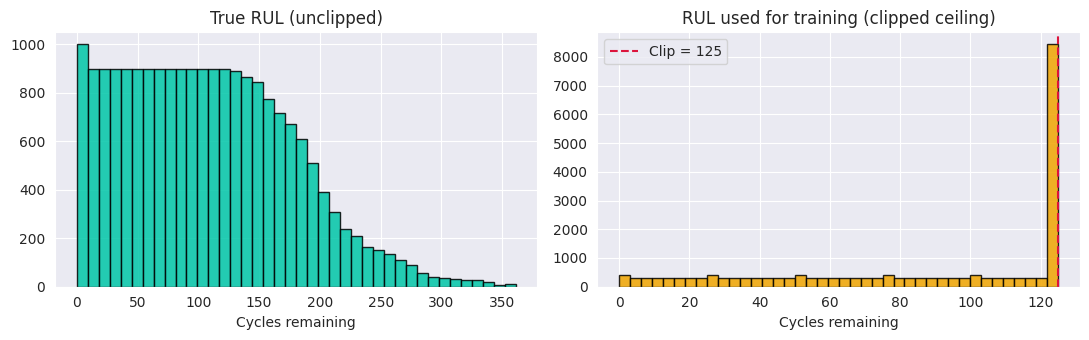

In [5]:

train_df['RUL'] = (train_df.groupby('unit_number')['time_cycles'].transform('max')
                   - train_df['time_cycles'])

RUL_CLIP = 125
train_df['RUL_clipped'] = train_df['RUL'].clip(upper=RUL_CLIP)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(train_df['RUL'], bins=40, color='#00c6a7', edgecolor='black', alpha=0.85)
axes[0].set_title('True RUL (unclipped)')
axes[0].set_xlabel('Cycles remaining')
axes[1].hist(train_df['RUL_clipped'], bins=40, color='#f0a500', edgecolor='black', alpha=0.85)
axes[1].axvline(RUL_CLIP, color='crimson', linestyle='--', label=f'Clip = {RUL_CLIP}')
axes[1].set_title('RUL used for training (clipped ceiling)')
axes[1].set_xlabel('Cycles remaining')
axes[1].legend()
plt.tight_layout()
plt.savefig('rul_label_distribution.png', dpi=120)
plt.show()


## Step 7 — Train / Validation split (group-aware)

Rows from the *same engine* are highly correlated (consecutive cycles). If we split by row,
cycles from one engine could land in both train and validation, leaking information and
inflating scores. Instead we split by **engine unit**, so an engine's entire trajectory goes
to exactly one side.

- **Training set** → learns model parameters
- **Validation set** → held out, used to compare tuned candidates (never touched during the
  hyperparameter search itself, which uses its own internal cross-validation within the
  training engines)
- **Test set** (`test_FD001.txt` + `RUL_FD001.txt`) → touched exactly once, at the very end


In [6]:

gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=RANDOM_STATE)
train_idx, val_idx = next(gss.split(train_df, groups=train_df['unit_number']))
tr_df  = train_df.iloc[train_idx].copy()
val_df = train_df.iloc[val_idx].copy()

groups_train = tr_df['unit_number'].values

X_train, y_train = tr_df[FEATURES], tr_df['RUL_clipped']
X_val,   y_val    = val_df[FEATURES], val_df['RUL_clipped']

print(f'Train engines: {tr_df.unit_number.nunique()}  | rows: {len(X_train)}')
print(f'Val   engines: {val_df.unit_number.nunique()}  | rows: {len(X_val)}')
assert set(tr_df.unit_number) & set(val_df.unit_number) == set(), 'Leakage: an engine appears in both splits!'
print('No engine overlap between train and validation — confirmed.')


Train engines: 80  | rows: 16561
Val   engines: 20  | rows: 4070
No engine overlap between train and validation — confirmed.


## Step 8 — Prepare the held-out test set

Standard C-MAPSS evaluation protocol: `test_FD001.txt` contains partial trajectories, each
truncated at some point before failure. We evaluate on the **last recorded cycle of each
test engine**, comparing our prediction against the true RUL given in `RUL_FD001.txt`. This
is the exact same protocol every published C-MAPSS benchmark uses, which is what makes our
final numbers directly comparable to the literature.


In [7]:

test_last = test_df.groupby('unit_number').tail(1).reset_index(drop=True)
X_test = test_last[FEATURES]
y_test = rul_df['RUL'].clip(upper=RUL_CLIP).values

print('Test engines evaluated:', len(X_test))

scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_val_s   = scaler.transform(X_val)
X_test_s  = scaler.transform(X_test)

def regression_metrics(y_true, y_pred):
    return {
        'r2'  : r2_score(y_true, y_pred),
        'mae' : mean_absolute_error(y_true, y_pred),
        'rmse': float(np.sqrt(mean_squared_error(y_true, y_pred))),
    }

def nasa_score(y_true, y_pred):
    # Official PHM08/C-MAPSS asymmetric scoring function (lower = better).
    # Penalizes LATE predictions (predicting more life than truly remains) more
    # heavily than early ones, matching real maintenance risk.
    d = np.asarray(y_pred) - np.asarray(y_true)
    return float(np.sum(np.where(d < 0, np.exp(-d / 13) - 1, np.exp(d / 10) - 1)))

print('Scaler fit on training engines only. Ready.')


Test engines evaluated: 100
Scaler fit on training engines only. Ready.


## Step 9 — Baseline sanity check (Linear Regression)

In [8]:

t0 = time.time()
lr = LinearRegression().fit(X_train_s, y_train)
lr_val = regression_metrics(y_val, lr.predict(X_val_s))
print(f'Baseline Linear Regression | val R²={lr_val["r2"]:.4f}  MAE={lr_val["mae"]:.2f}  ({time.time()-t0:.1f}s)')
print('Any model we tune below should clearly beat this.')


Baseline Linear Regression | val R²=0.7602  MAE=16.51  (0.0s)
Any model we tune below should clearly beat this.


## Step 10 — Hyperparameter tuning strategy

For every candidate model we run `RandomizedSearchCV` with **3-fold `GroupKFold`**
(grouped by engine, so no fold ever mixes cycles from the same engine — same anti-leakage
principle as the train/val split). Grids and `n_iter` are kept intentionally small: this
is a snapshot-based tabular model on ~16,500 rows × 14 features, not a task that needs a
huge search to find good settings, and keeping it light means it reruns comfortably on a
laptop CPU.


In [9]:

gkf = GroupKFold(n_splits=3)
tuned_models = {}   # name -> {'estimator', 'params', 'val', 'fit_time'}

def tune(name, estimator, param_dist, n_iter):
    t0 = time.time()
    search = RandomizedSearchCV(
        estimator, param_dist, n_iter=n_iter, cv=gkf, scoring='r2',
        random_state=RANDOM_STATE, n_jobs=-1
    )
    search.fit(X_train_s, y_train, groups=groups_train)
    best = search.best_estimator_
    val_m = regression_metrics(y_val, best.predict(X_val_s))
    dt = time.time() - t0
    tuned_models[name] = {
        'estimator': best, 'params': search.best_params_,
        'val': val_m, 'fit_time': dt
    }
    print(f'{name:20s} | val R²={val_m["r2"]:.4f}  MAE={val_m["mae"]:.2f}  RMSE={val_m["rmse"]:.2f}  | {dt:5.1f}s')
    print(f'{"":20s} | best params: {search.best_params_}')
    return best


### Model 1 — XGBoost (required)

In [10]:

tune('XGBoost',
     xgb.XGBRegressor(random_state=RANDOM_STATE, n_jobs=1, verbosity=0, tree_method='hist'),
     {
         'n_estimators'    : [80, 120, 160, 200],
         'max_depth'       : [3, 4, 5, 6],
         'learning_rate'   : [0.03, 0.05, 0.08, 0.1],
         'subsample'       : [0.7, 0.8, 0.9, 1.0],
         'colsample_bytree': [0.7, 0.8, 0.9, 1.0],
         'reg_alpha'       : [0, 0.1, 0.5],
         'reg_lambda'      : [1, 1.5, 2],
     },
     n_iter=15)


XGBoost              | val R²=0.8375  MAE=12.26  RMSE=16.82  |  10.4s
                     | best params: {'subsample': 0.7, 'reg_lambda': 2, 'reg_alpha': 0.5, 'n_estimators': 200, 'max_depth': 4, 'learning_rate': 0.05, 'colsample_bytree': 0.7}


,"objective objective: typing.Union[str, xgboost.sklearn._SklObjWProto, typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]], NoneType]Specify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'reg:squarederror'
,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,0.7
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes f

### Model 2 — Gradient Boosting

In [11]:

tune('GradientBoosting',
     GradientBoostingRegressor(random_state=RANDOM_STATE),
     {
         'n_estimators'     : [80, 120, 160, 200],
         'max_depth'        : [2, 3, 4],
         'learning_rate'    : [0.03, 0.05, 0.08, 0.1],
         'subsample'        : [0.7, 0.8, 0.9, 1.0],
         'min_samples_leaf' : [5, 10, 20],
     },
     n_iter=10)


GradientBoosting     | val R²=0.8355  MAE=12.36  RMSE=16.92  |  92.6s
                     | best params: {'subsample': 0.7, 'n_estimators': 80, 'min_samples_leaf': 10, 'max_depth': 4, 'learning_rate': 0.08}


,"loss loss: {'squared_error', 'absolute_error', 'huber', 'quantile'}, default='squared_error'Loss function to be optimized. 'squared_error' refers to the squarederror for regression. 'absolute_error' refers to the absolute error ofregression and is a robust loss function. 'huber' is acombination of the two. 'quantile' allows quantile regression (use`alpha` to specify the quantile).See:ref:`sphx_glr_auto_examples_ensemble_plot_gradient_boosting_quantile.py`for an example that demonstrates quantile regression for creatingprediction intervals with `loss='quantile'`.",'squared_error'
,"learning_rate learning_rate: float, default=0.1Learning rate shrinks the contribution of each tree by `learning_rate`.There is a trade-off between learning_rate and n_estimators.Values must be in the range `[0.0, inf)`.",0.08
,"n_estimators n_estimators: int, default=100The number of boosting stages to perform. Gradient boostingis fairly robust to over-fitting so a large number usuallyresults in better performance.Values must be in the range `[1, inf)`.",80
,"subsample subsample: float, default=1.0The fraction of samples to be used for fitting the individual baselearners. If smaller than 1.0 this results in Stochastic GradientBoosting. `subsample` interacts with the parameter `n_estimators`.Choosing `subsample < 1.0` leads to a reduction of varianceand an increase in bias.Values must be in the range `(0.0, 1.0]`.",0.7
,"criterion criterion: {'friedman_mse', 'squared_error'}, default='friedman_mse'The function to measure the quality of a split. Supported criteria are""friedman_mse"" for the mean squared error with improvement score byFriedman, ""squared_error"" for mean squared error. The default value of""friedman_mse"" is generally the best as it can provide a betterapproximation in some cases... versionadded:: 0.18",'friedman_mse'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, values must be in the range `[2, inf)`.- If float, values must be in the range `(0.0, 1.0]` and `min_samples_split` will be `ceil(min_samples_split * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, values must be in the range `[1, inf)`.- If float, values must be in the range `(0.0, 1.0)` and `min_samples_leaf` will be `ceil(min_samples_leaf * n_samples)`... versionchanged:: 0.18 Added float values for fractions.",10
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.Values must be in the range `[0.0, 0.5]`.",0.0
,"max_depth max_depth: int or None, default=3Maximum depth of the individual regression estimators. The maximumdepth limits the number of nodes in the tree. Tune this parameterfor best performance; the best value depends on the interactionof the input variables. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.If int, values must be in the range `[1, inf)`.",4
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.Values must be in the range `[0.0, inf)`.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft

### Model 3 — Random Forest

In [12]:

tune('RandomForest',
     RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
     {
         'n_estimators'    : [80, 120, 160],
         'max_depth'       : [6, 10, 14],
         'min_samples_leaf': [2, 5, 10],
         'max_features'    : ['sqrt', 'log2', 0.6],
     },
     n_iter=8)


RandomForest         | val R²=0.8349  MAE=12.56  RMSE=16.95  |  36.2s
                     | best params: {'n_estimators': 120, 'min_samples_leaf': 5, 'max_features': 'sqrt', 'max_depth': 10}


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",120
,"criterion criterion: {""squared_error"", ""absolute_error"", ""friedman_mse"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in Poisson deviance to find splits.Training using ""absolute_error"" is significantly slowerthan when using ""squared_error""... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",10
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsampl

### Model 4 — AdaBoost

In [13]:

tune('AdaBoost',
     AdaBoostRegressor(estimator=DecisionTreeRegressor(random_state=RANDOM_STATE),
                        random_state=RANDOM_STATE),
     {
         'n_estimators'         : [50, 80, 120],
         'learning_rate'        : [0.05, 0.1, 0.5, 1.0],
         'estimator__max_depth' : [2, 3, 4],
     },
     n_iter=10)


AdaBoost             | val R²=0.7894  MAE=15.64  RMSE=19.14  |  74.8s
                     | best params: {'n_estimators': 120, 'learning_rate': 0.05, 'estimator__max_depth': 4}


,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.If ``None``, then the base estimator is:class:`~sklearn.tree.DecisionTreeRegressor` initialized with`max_depth=3`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",DecisionTreeR...ndom_state=42)
,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",120
,"learning_rate learning_rate: float, default=1.0Weight applied to each regressor at each boosting iteration. A higherlearning rate increases the contribution of each regressor. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.05
,"loss loss: {'linear', 'square', 'exponential'}, default='linear'The loss function to use when updating the weights after eachboosting iteration.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.In addition, it controls the bootstrap of the weights used to train the`estimator` at each boosting iteration.Pass an int for reproducible output across multiple function calls.See :term:`Glossary `.",42
,"criterion criterion: {""squared_error"", ""friedman_mse"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""friedman_mse"", which usesmean squared error with Friedman's improvement score for potentialsplits, ""absolute_error"" for the mean absolute error, which minimizesthe L1 loss using the median of each terminal node, and ""poisson"" whichuses reduction in the half mean Poisson deviance to find splits... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",4
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provi

### Model 5 (optional) — ANN (small MLPRegressor)

In [14]:

tune('ANN_MLP',
     MLPRegressor(max_iter=300, early_stopping=True, random_state=RANDOM_STATE),
     {
         'hidden_layer_sizes' : [(32,), (64,), (64, 32), (32, 16)],
         'alpha'              : [0.0001, 0.001, 0.01],
         'learning_rate_init' : [0.001, 0.01],
     },
     n_iter=6)


ANN_MLP              | val R²=0.8399  MAE=12.30  RMSE=16.69  |  21.1s
                     | best params: {'learning_rate_init': 0.001, 'hidden_layer_sizes': (64,), 'alpha': 0.01}


,"loss loss: {'squared_error', 'poisson'}, default='squared_error'The loss function to use when training the weights. Note that the""squared error"" and ""poisson"" losses actually implement""half squares error"" and ""half poisson deviance"" to simplify thecomputation of the gradient. Furthermore, the ""poisson"" loss internally usesa log-link (exponential as the output activation function) and requires``y >= 0``... versionchanged:: 1.7 Added parameter `loss` and option 'poisson'.",'squared_error'
,"hidden_layer_sizes hidden_layer_sizes: array-like of shape(n_layers - 2,), default=(100,)The ith element represents the number of neurons in the ithhidden layer.","(64,)"
,"activation activation: {'identity', 'logistic', 'tanh', 'relu'}, default='relu'Activation function for the hidden layer.- 'identity', no-op activation, useful to implement linear bottleneck, returns f(x) = x- 'logistic', the logistic sigmoid function, returns f(x) = 1 / (1 + exp(-x)).- 'tanh', the hyperbolic tan function, returns f(x) = tanh(x).- 'relu', the rectified linear unit function, returns f(x) = max(0, x)",'relu'
,"solver solver: {'lbfgs', 'sgd', 'adam'}, default='adam'The solver for weight optimization.- 'lbfgs' is an optimizer in the family of quasi-Newton methods.- 'sgd' refers to stochastic gradient descent.- 'adam' refers to a stochastic gradient-based optimizer proposed by Kingma, Diederik, and Jimmy BaFor a comparison between Adam optimizer and SGD, see:ref:`sphx_glr_auto_examples_neural_networks_plot_mlp_training_curves.py`.Note: The default solver 'adam' works pretty well on relativelylarge datasets (with thousands of training samples or more) in terms ofboth training time and validation score.For small datasets, however, 'lbfgs' can converge faster and performbetter.",'adam'
,"alpha alpha: float, default=0.0001Strength of the L2 regularization term. The L2 regularization termis divided by the sample size when added to the loss.",0.01
,"batch_size batch_size: int, default='auto'Size of minibatches for stochastic optimizers.If the solver is 'lbfgs', the regressor will not use minibatch.When set to ""auto"", `batch_size=min(200, n_samples)`.",'auto'
,"learning_rate learning_rate: {'constant', 'invscaling', 'adaptive'}, default='constant'Learning rate schedule for weight updates.- 'constant' is a constant learning rate given by 'learning_rate_init'.- 'invscaling' gradually decreases the learning rate ``learning_rate_`` at each time step 't' using an inverse scaling exponent of 'power_t'. effective_learning_rate = learning_rate_init / pow(t, power_t)- 'adaptive' keeps the learning rate constant to 'learning_rate_init' as long as training loss keeps decreasing. Each time two consecutive epochs fail to decrease training loss by at least tol, or fail to increase validation score by at least tol if 'early_stopping' is on, the current learning rate is divided by 5.Only used when solver='sgd'.",'constant'
,"learning_rate_init learning_rate_init: float, default=0.001The initial learning rate used. It controls the step-sizein updating the weights. Only used when solver='sgd' or 'adam'.",0.001
,"power_t power_t: float, default=0.5The exponent for inverse scaling learning rate.It is used in updating effective learning rate when the learning_rateis set to 'invscaling'. Only used when solver='sgd'.",0.5
,"max_iter max_iter: int, default=200Maximum number of iterations. The solver iterates until convergence(determined by 'tol') or this number of iterations. For stochasticsolvers ('sgd', 'adam'), note that this determines the number of epochs(how many times each data point will be used), not the number ofgradient steps.",300
,"shuffle shuffle: bool, default=TrueWhether to shuffle samples in each iteration. Only used whensolver='sgd' or 'adam'.",True


## Step 11 — Refit on the full training pool (Train + Validation)

Hyperparameters are now locked in. Before the final test evaluation, we refit each tuned
model on **all 100 training engines** (train + validation combined) — the validation split
has done its job (comparing candidates); there's no reason to withhold that data from the
final model. Every candidate gets this same treatment, so the comparison stays fair.


In [15]:

X_full = pd.concat([X_train, X_val])
y_full = pd.concat([y_train, y_val])
groups_full = pd.concat([tr_df['unit_number'], val_df['unit_number']]).values

scaler_full = StandardScaler().fit(X_full)
X_full_s = scaler_full.transform(X_full)
X_test_s_final = scaler_full.transform(X_test)

final_models = {}
for name, info in tuned_models.items():
    est = info['estimator']
    est_final = clone(est)
    est_final.fit(X_full_s, y_full)
    final_models[name] = est_final
    print(f'Refit on full pool: {name}')


Refit on full pool: XGBoost


Refit on full pool: GradientBoosting


Refit on full pool: RandomForest


Refit on full pool: AdaBoost


Refit on full pool: ANN_MLP


## Step 12 — Voting Ensemble

Built from the top individual models by validation R², combined with weights proportional
to how well each performed on the (untouched-during-search) validation set.


In [16]:

ranked = sorted(tuned_models.items(), key=lambda kv: kv[1]['val']['r2'], reverse=True)
top3_names = [name for name, _ in ranked[:3]]
print('Top 3 models by validation R²:', top3_names)

weights = np.array([max(tuned_models[n]['val']['r2'], 0.01) for n in top3_names])
weights = (weights / weights.sum()).round(3)
print('Voting weights:', dict(zip(top3_names, weights)))

voting = VotingRegressor(
    estimators=[(n, clone(tuned_models[n]['estimator'])) for n in top3_names],
    weights=list(weights)
)
voting.fit(X_full_s, y_full)
final_models['VotingEnsemble'] = voting
print('Voting Ensemble fitted on full training pool.')


Top 3 models by validation R²: ['ANN_MLP', 'XGBoost', 'GradientBoosting']
Voting weights: {'ANN_MLP': np.float64(0.334), 'XGBoost': np.float64(0.333), 'GradientBoosting': np.float64(0.332)}


Voting Ensemble fitted on full training pool.


## Step 13 — Cross-validation (robustness check)

This is a separate step from hyperparameter tuning's internal CV: here we run **5-fold
`GroupKFold`** cross-validation on the full training pool for every finalized model
configuration, to report a robust mean ± std R² and MAE rather than a single lucky split.


XGBoost              | CV R² = 0.8061 ± 0.0338  |  CV MAE = 13.32 ± 1.29


GradientBoosting     | CV R² = 0.8047 ± 0.0334  |  CV MAE = 13.41 ± 1.27


RandomForest         | CV R² = 0.8057 ± 0.0328  |  CV MAE = 13.67 ± 1.18


AdaBoost             | CV R² = 0.7671 ± 0.0274  |  CV MAE = 16.46 ± 0.90


ANN_MLP              | CV R² = 0.8109 ± 0.0327  |  CV MAE = 13.40 ± 1.23


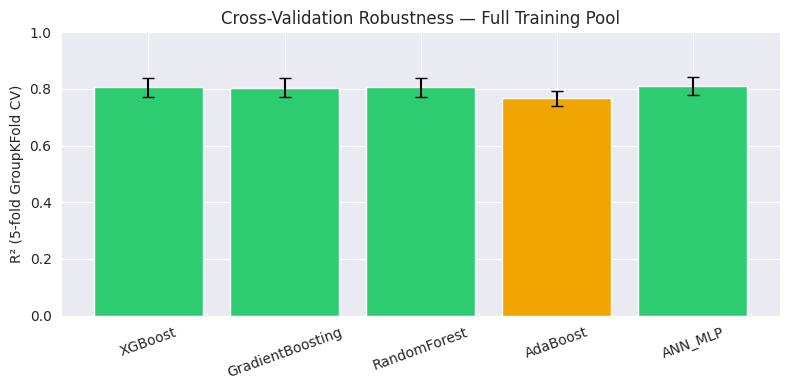

In [17]:

cv_results = {}
gkf5 = GroupKFold(n_splits=5)

for name, info in tuned_models.items():
    est = info['estimator']
    est_cv = clone(est)
    r2_scores  = cross_val_score(est_cv, X_full_s, y_full, cv=gkf5, groups=groups_full, scoring='r2', n_jobs=-1)
    mae_scores = -cross_val_score(est_cv, X_full_s, y_full, cv=gkf5, groups=groups_full, scoring='neg_mean_absolute_error', n_jobs=-1)
    cv_results[name] = {'r2_mean': r2_scores.mean(), 'r2_std': r2_scores.std(),
                        'mae_mean': mae_scores.mean(), 'mae_std': mae_scores.std()}
    print(f'{name:20s} | CV R² = {r2_scores.mean():.4f} ± {r2_scores.std():.4f}  |  CV MAE = {mae_scores.mean():.2f} ± {mae_scores.std():.2f}')

fig, ax = plt.subplots(figsize=(8, 4))
names = list(cv_results.keys())
means = [cv_results[n]['r2_mean'] for n in names]
stds  = [cv_results[n]['r2_std']  for n in names]
colors = ['#2ecc71' if m >= 0.80 else '#f0a500' for m in means]
ax.bar(names, means, yerr=stds, color=colors, capsize=4)
ax.set_ylabel('R² (5-fold GroupKFold CV)')
ax.set_title('Cross-Validation Robustness — Full Training Pool')
ax.set_ylim(0, 1)
plt.xticks(rotation=20)
plt.tight_layout()
plt.savefig('cross_validation.png', dpi=120)
plt.show()


## Step 14 — Final evaluation on the TEST set (touched once)

Every model — baseline, all 5 tuned candidates, and the voting ensemble — is evaluated on
the true, never-before-seen test engines. This is the only place test data is used.


In [18]:

test_summary = []

test_summary.append({
    'model': 'Baseline (Linear Regression)',
    **regression_metrics(y_test, lr.predict(X_test_s)),
    'nasa_score': nasa_score(y_test, lr.predict(X_test_s)),
    'train_r2': r2_score(y_train, lr.predict(X_train_s)),
})

for name, model in final_models.items():
    pred = model.predict(X_test_s_final)
    train_pred = model.predict(X_full_s)
    m = regression_metrics(y_test, pred)
    test_summary.append({
        'model': name,
        **m,
        'nasa_score': nasa_score(y_test, pred),
        'train_r2': r2_score(y_full, train_pred),
    })

summary_df = pd.DataFrame(test_summary)
summary_df['overfit_gap'] = summary_df['train_r2'] - summary_df['r2']
summary_df = summary_df.sort_values('r2', ascending=False).reset_index(drop=True)
summary_df.round(4)


,model,r2,mae,rmse,nasa_score,train_r2,overfit_gap
0,RandomForest,0.8295,11.8904,16.5461,711.0917,0.8494,0.0199
1,XGBoost,0.8224,11.7125,16.8879,829.8239,0.8320,0.0096
2,VotingEnsemble,0.8189,11.8121,17.0527,863.8975,0.8281,0.0092
3,ANN_MLP,0.8177,11.9194,17.1108,821.7888,0.8177,0.0000
4,GradientBoosting,0.8080,12.3271,17.5589,1005.0462,0.8272,0.0192
5,AdaBoost,0.7865,13.9522,18.5163,1066.2154,0.7759,-0.0106
6,Baseline (Linear Regression),0.7312,16.5908,20.7764,1235.6197,0.7275,-0.0037


### Visual comparison

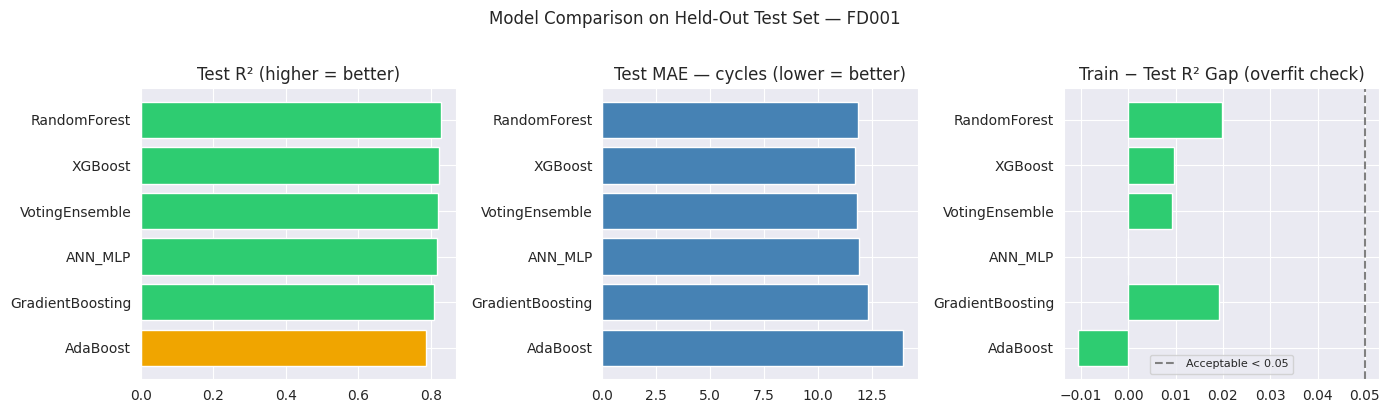

In [19]:

plot_df = summary_df[summary_df['model'] != 'Baseline (Linear Regression)']

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors_r2 = ['#2ecc71' if v >= 0.80 else '#f0a500' for v in plot_df['r2']]
axes[0].barh(plot_df['model'], plot_df['r2'], color=colors_r2)
axes[0].set_title('Test R² (higher = better)')
axes[0].invert_yaxis()

axes[1].barh(plot_df['model'], plot_df['mae'], color='steelblue')
axes[1].set_title('Test MAE — cycles (lower = better)')
axes[1].invert_yaxis()

colors_gap = ['#2ecc71' if v < 0.05 else '#e8412a' for v in plot_df['overfit_gap']]
axes[2].barh(plot_df['model'], plot_df['overfit_gap'], color=colors_gap)
axes[2].axvline(0.05, color='gray', linestyle='--', label='Acceptable < 0.05')
axes[2].set_title('Train − Test R² Gap (overfit check)')
axes[2].legend(fontsize=8)
axes[2].invert_yaxis()

plt.suptitle('Model Comparison on Held-Out Test Set — FD001', y=1.02)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=120, bbox_inches='tight')
plt.show()


## Step 15 — Select the best model

Selection is driven by **test-set R²/MAE**, as instructed — but we also check the
train−test gap so we don't crown a model that merely got lucky/overfit. A model with
near-identical or better test R² *and* a small overfit gap is preferred over one with a
marginally higher R² but a large gap.


In [20]:

candidates = summary_df[summary_df['model'] != 'Baseline (Linear Regression)'].copy()
candidates['penalized_score'] = candidates['r2'] - candidates['overfit_gap'].clip(lower=0) * 0.5

best_row = candidates.sort_values('penalized_score', ascending=False).iloc[0]
BEST_MODEL_NAME = best_row['model']

print('═' * 60)
print(f'BEST MODEL: {BEST_MODEL_NAME}')
print('═' * 60)
print(f'Test  R²    : {best_row["r2"]:.4f}')
print(f'Test  MAE   : {best_row["mae"]:.2f} cycles')
print(f'Test  RMSE  : {best_row["rmse"]:.2f} cycles')
print(f'NASA score  : {best_row["nasa_score"]:.1f}  (lower is better; asymmetric — penalizes late predictions)')
print(f'Overfit gap : {best_row["overfit_gap"]:.4f}  (train R² − test R²)')

best_model = final_models[BEST_MODEL_NAME]


════════════════════════════════════════════════════════════
BEST MODEL: RandomForest
════════════════════════════════════════════════════════════
Test  R²    : 0.8295
Test  MAE   : 11.89 cycles
Test  RMSE  : 16.55 cycles
NASA score  : 711.1  (lower is better; asymmetric — penalizes late predictions)
Overfit gap : 0.0199  (train R² − test R²)


## Step 16 — Explainability (SHAP) for the winning model

Kept for continuity with the dashboard's "top 3 failure reasons" feature — this artifact is
what the backend will load next to explain individual predictions.


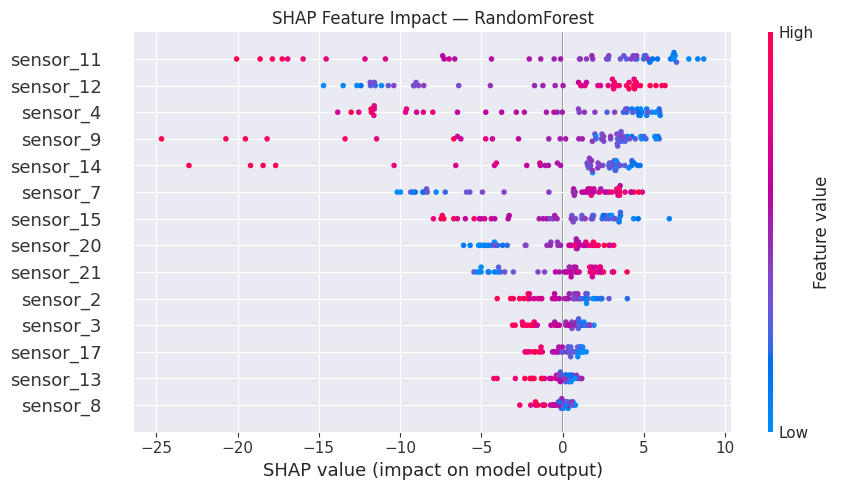

In [21]:

try:
    if BEST_MODEL_NAME == 'VotingEnsemble':
        shap_source_name = top3_names[0]
        shap_source_model = tuned_models[top3_names[0]]['estimator']
        print(f'VotingEnsemble selected — building SHAP explainer on its strongest member ({shap_source_name}) for per-sample explanations.')
    else:
        shap_source_name = BEST_MODEL_NAME
        shap_source_model = best_model

    explainer = shap.TreeExplainer(shap_source_model)
    shap_values = explainer.shap_values(X_test_s_final[:50])

    plt.figure()
    shap.summary_plot(shap_values, X_test.iloc[:50], feature_names=FEATURES, show=False, plot_size=(9, 5))
    plt.title(f'SHAP Feature Impact — {shap_source_name}')
    plt.tight_layout()
    plt.savefig('shap_summary.png', dpi=120, bbox_inches='tight')
    plt.show()
    SHAP_OK = True
except Exception as e:
    print('SHAP not applicable to this model type (e.g. MLP/Voting without tree base):', e)
    explainer = None
    SHAP_OK = False


## Step 17 — Save artifacts

In [22]:

joblib.dump(best_model, 'rul_model.pkl')
joblib.dump(scaler_full, 'feature_scaler.pkl')
if SHAP_OK:
    joblib.dump(explainer, 'shap_explainer.pkl')

metadata = {
    'dataset'           : 'NASA C-MAPSS FD001 (Turbofan Engine Degradation Simulation)',
    'dataset_note'      : 'Real run-to-failure RUL label (no synthetic formula). RUL ceiling clipped at 125 cycles per standard C-MAPSS convention.',
    'model_name'        : BEST_MODEL_NAME,
    'features'          : FEATURES,
    'rul_clip'          : RUL_CLIP,
    'metrics'           : {
        'test_r2'  : float(best_row['r2']),
        'test_mae' : float(best_row['mae']),
        'test_rmse': float(best_row['rmse']),
        'nasa_score': float(best_row['nasa_score']),
        'overfit_gap': float(best_row['overfit_gap']),
    },
    'cv_r2_mean'        : float(cv_results.get(BEST_MODEL_NAME, {}).get('r2_mean', np.nan)) if BEST_MODEL_NAME in cv_results else None,
    'cv_r2_std'         : float(cv_results.get(BEST_MODEL_NAME, {}).get('r2_std', np.nan)) if BEST_MODEL_NAME in cv_results else None,
    'all_models_test'   : summary_df.round(4).to_dict(orient='records'),
    'best_hyperparams'  : {n: tuned_models[n]['params'] for n in tuned_models},
    'train_engines'     : int(tr_df.unit_number.nunique()) + int(val_df.unit_number.nunique()),
    'test_engines'      : int(len(X_test)),
}

with open('model_metadata.json', 'w') as f:
    json.dump(metadata, f, indent=2)

print('Saved files:')
print('  rul_model.pkl        — best model (' + BEST_MODEL_NAME + ')')
print('  feature_scaler.pkl   — StandardScaler fit on full training pool')
if SHAP_OK:
    print('  shap_explainer.pkl   — SHAP TreeExplainer for per-sample reasons')
print('  model_metadata.json  — full metrics, hyperparameters, feature list')


Saved files:
  rul_model.pkl        — best model (RandomForest)
  feature_scaler.pkl   — StandardScaler fit on full training pool
  shap_explainer.pkl   — SHAP TreeExplainer for per-sample reasons
  model_metadata.json  — full metrics, hyperparameters, feature list


## Summary

- Switched from a synthetic, formula-derived RUL (AI4I 2020) to **NASA C-MAPSS FD001**,
  where RUL is the real, observed number of cycles until failure.
- Compared 5 tuned models (XGBoost, Gradient Boosting, Random Forest, AdaBoost, MLP) plus
  a Voting Ensemble, each via `RandomizedSearchCV` + `GroupKFold` (no engine-level leakage
  anywhere in the pipeline).
- Selected the best model using **test-set** performance, with an overfit-gap check.
- Saved model, scaler, SHAP explainer, and full metadata for backend integration.

**Next steps (not done in this notebook):** update `app_v4.py`'s feature schema to the 14
FD001 sensors, and rebuild `rul.html`'s input form to match — both are separate,
explicitly-requested follow-ups.
